<a href="https://colab.research.google.com/github/iipingebnaa/Intensive-Big-Data-Analytics-Project/blob/main/06_PCA_Deployment/RetailMart_PCA_and_Deployment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook builds on the cleaned RetailMart dataset and the techniques developed in the earlier project deliverables.

Step 1: Set up the environment

In [2]:
# Step 1: Import and verify the libraries needed for PCA and deployment

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Current working directory:", os.getcwd())
print("\nEnvironment check completed.")

NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
Current working directory: /content

Environment check completed.


Step 2 — Upload the cleaned RetailMart dataset

In [3]:
# Step 2: Upload the cleaned RetailMart dataset

from google.colab import files

uploaded = files.upload()

print("\nUploaded file(s):")
for filename in uploaded.keys():
    print(filename)

Saving retailmart_transactions_cleaned.csv to retailmart_transactions_cleaned.csv

Uploaded file(s):
retailmart_transactions_cleaned.csv


Step 3 — Load and inspect the dataset

In [17]:
# Step 3: Load and inspect the cleaned RetailMart dataset

import pandas as pd
import os

if os.path.exists("/content/retailmart_transactions_cleaned.parquet"):
    file_path = "/content/retailmart_transactions_cleaned.parquet"
    df = pd.read_parquet(file_path)

elif os.path.exists("/content/retailmart_transactions_cleaned.csv"):
    file_path = "/content/retailmart_transactions_cleaned.csv"
    df = pd.read_csv(file_path)

else:
    raise FileNotFoundError(
        "The expected dataset was not found. "
        "Check the uploaded filename in Step 2."
    )

print("Dataset loaded successfully.")
print("File:", file_path)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully.
File: /content/retailmart_transactions_cleaned.csv
Number of rows: 973266
Number of columns: 15

Column names:
['transaction_id', 'customer_id', 'transaction_date', 'product_category', 'product_name', 'quantity', 'unit_price', 'total_amount', 'store_location', 'payment_method', 'customer_age', 'customer_gender', 'loyalty_years', 'num_visits', 'churn']

First five rows:


,transaction_id,customer_id,transaction_date,product_category,product_name,quantity,unit_price,total_amount,store_location,payment_method,customer_age,customer_gender,loyalty_years,num_visits,churn
0,TXN-00000001,9917ffd9-acc9-49fc-8ac1-dbc79420889f,2022-04-03 10:47:06,Clothing,T-Shirt,1,43.13,43.13,"Dallas, TX",Debit Card,49.0,Non-Binary,3,12,No
1,TXN-00000002,0883f296-153c-4b62-ad0d-036c3d3984b5,2021-03-03 09:13:14,Clothing,Dress,1,55.36,55.36,"Denver, CO",Credit Card,65.0,Unknown,0,4,No
2,TXN-00000003,8976c6e4-9042-4de3-8551-0275d0acaa96,2022-03-28 15:37:17,Groceries,Cereal,2,15.42,30.84,"Las Vegas, NV",Mobile Pay,18.0,Male,1,6,No
3,TXN-00000004,287ce01e-0d82-4a1e-b34e-3212e940b9b3,2022-07-24 10:13:48,Home & Kitchen,Dinnerware,1,87.83,87.83,"Denver, CO",Cash,33.0,Male,2,8,No
4,TXN-00000005,b5b5845e-822e-4dbb-a17a-48fb614810e8,2024-05-21 12:51:02,Toys,Action Figure,1,34.94,34.94,"Boston, MA",Cash,33.0,Male,7,16,No


Step 4 — Prepare the numerical features

In [18]:
# Step 4: Select and prepare numerical features for PCA

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Select numerical customer and transaction features
pca_features = [
    "quantity",
    "unit_price",
    "total_amount",
    "customer_age",
    "loyalty_years",
    "num_visits"
]

# Create a separate feature dataset
X_pca = df[pca_features].copy()

# Convert selected columns to numeric values
X_pca = X_pca.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
X_pca = X_pca.replace([float("inf"), float("-inf")], float("nan"))

# Fill missing values using the median
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_pca)

# Standardize features so variables with larger scales
# do not dominate PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("PCA feature preparation completed.")
print("Number of records:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])
print("\nFeatures used:")
print(pca_features)
print("\nMissing values after imputation:", int(pd.isna(X_imputed).sum()))
print("Scaled feature means (approximately zero):")
print(X_scaled.mean(axis=0).round(4))

PCA feature preparation completed.
Number of records: 973266
Number of features: 6

Features used:
['quantity', 'unit_price', 'total_amount', 'customer_age', 'loyalty_years', 'num_visits']

Missing values after imputation: 0
Scaled feature means (approximately zero):
[-0.  0. -0. -0.  0.  0.]


Step 5 — Apply PCA and measure explained variance

In [19]:
# Step 5: Apply Principal Component Analysis (PCA)

from sklearn.decomposition import PCA

# Fit PCA using the standardized numerical features
pca = PCA()
X_pca_transformed = pca.fit_transform(X_scaled)

# Calculate the explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

# Create a results table
pca_results = pd.DataFrame({
    "Principal Component": [
        f"PC{i + 1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("PCA completed successfully.")
display(pca_results.round(2))

# Find the number of components needed to retain at least 90% variance
components_90 = int(
    (cumulative_variance < 0.90).sum() + 1
)

print(
    f"\nComponents needed to retain at least 90% of the variance: "
    f"{components_90} out of {len(pca_features)}"
)
print(
    f"Variance retained by those components: "
    f"{cumulative_variance[components_90 - 1] * 100:.2f}%"
)

PCA completed successfully.


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,31.01,31.01
1,PC2,30.60,61.61
2,PC3,16.68,78.29
3,PC4,16.64,94.94
4,PC5,2.74,97.67
5,PC6,2.33,100.00



Components needed to retain at least 90% of the variance: 4 out of 6
Variance retained by those components: 94.94%


Step 6 — Visualise explained variance

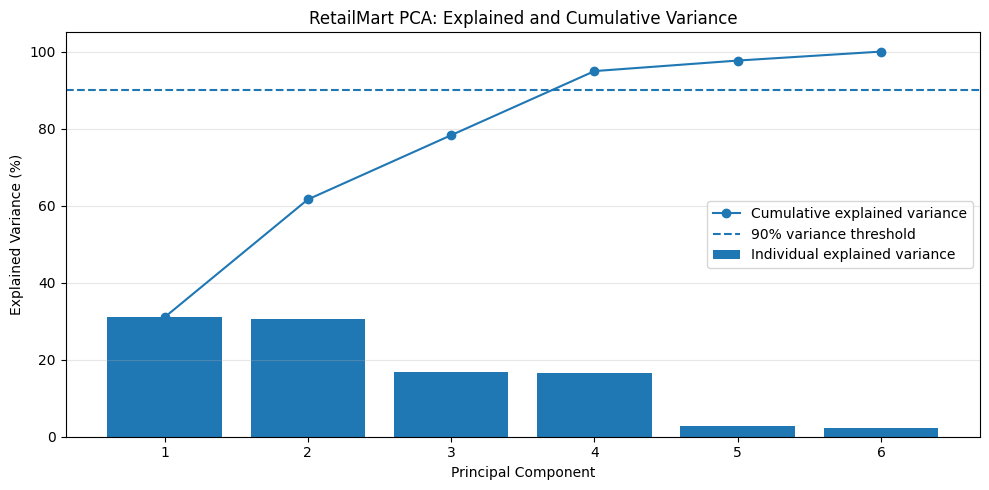

In [20]:
# Step 6: Visualise PCA explained and cumulative variance

components = range(1, len(explained_variance) + 1)

plt.figure(figsize=(10, 5))

plt.bar(
    components,
    explained_variance * 100,
    label="Individual explained variance"
)

plt.plot(
    components,
    cumulative_variance * 100,
    marker="o",
    label="Cumulative explained variance"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance threshold"
)

plt.xticks(list(components))
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("RetailMart PCA: Explained and Cumulative Variance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Step 7 — Create the reduced dataset using four principal components

In [21]:
# Step 7: Reduce the dataset to four principal components

from sklearn.decomposition import PCA

# Retain four components, which explain 94.94% of the variance
pca_reduced = PCA(n_components=4)

X_reduced = pca_reduced.fit_transform(X_scaled)

# Store the reduced data in a DataFrame
pca_columns = ["PC1", "PC2", "PC3", "PC4"]
df_pca = pd.DataFrame(X_reduced, columns=pca_columns)

print("PCA dimensionality reduction completed.")
print("Original feature count:", len(pca_features))
print("Reduced feature count:", X_reduced.shape[1])
print("Number of records:", X_reduced.shape[0])
print(
    "Variance retained:",
    f"{pca_reduced.explained_variance_ratio_.sum() * 100:.2f}%"
)

print("\nFirst five rows of the reduced dataset:")
display(df_pca.head())

PCA dimensionality reduction completed.
Original feature count: 6
Reduced feature count: 4
Number of records: 973266
Variance retained: 94.94%

First five rows of the reduced dataset:


,PC1,PC2,PC3,PC4
0,0.337444,-0.838344,0.084805,0.688944
1,-1.368141,-0.600228,0.893677,1.500717
2,-0.885249,-0.794540,-1.197089,-1.217078
3,-0.356007,-0.349016,-0.990349,0.186879
4,1.854245,-1.023607,-0.742902,-0.100299


Step 8 — Analyse PCA component loadings

In [22]:
# Step 8: Examine the contribution of original features to each component

loadings = pd.DataFrame(
    pca_reduced.components_.T,
    index=pca_features,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

print("PCA component loadings:")
display(loadings.round(3))

# Show the strongest contributing feature for each component
print("\nLargest absolute loading for each component:")

for component in loadings.columns:
    strongest_feature = loadings[component].abs().idxmax()
    loading_value = loadings.loc[strongest_feature, component]

    print(
        f"{component}: {strongest_feature} "
        f"(loading = {loading_value:.3f})"
    )

PCA component loadings:


,PC1,PC2,PC3,PC4
quantity,0.025,0.395,0.539,-0.630
unit_price,0.041,0.585,-0.365,0.424
total_amount,0.048,0.705,-0.000,-0.000
customer_age,0.000,0.001,0.759,0.651
loyalty_years,0.705,-0.048,0.001,-0.000
num_visits,0.705,-0.048,0.001,-0.002



Largest absolute loading for each component:
PC1: num_visits (loading = 0.705)
PC2: total_amount (loading = 0.705)
PC3: customer_age (loading = 0.759)
PC4: customer_age (loading = 0.651)


Step 9 — Build the reusable PCA transformation

In [23]:
# Step 9: Build a reusable preprocessing and PCA pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import joblib

# Combine preprocessing and PCA into one reusable pipeline
pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=4))
])

# Fit the pipeline on the selected numerical features
X_pca_pipeline = pca_pipeline.fit_transform(df[pca_features])

print("Reusable PCA pipeline created successfully.")
print("Input features:", len(pca_features))
print("Output components:", X_pca_pipeline.shape[1])
print(
    "Variance retained:",
    f"{pca_pipeline.named_steps['pca'].explained_variance_ratio_.sum() * 100:.2f}%"
)

Reusable PCA pipeline created successfully.
Input features: 6
Output components: 4
Variance retained: 94.94%


Step 10 — Save the PCA pipeline for deployment

In [24]:
# Step 10: Save the PCA pipeline

import joblib
import os

model_path = "/content/retailmart_pca_pipeline.joblib"

joblib.dump(pca_pipeline, model_path)

print("PCA pipeline saved successfully.")
print("File path:", model_path)
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

PCA pipeline saved successfully.
File path: /content/retailmart_pca_pipeline.joblib
File size: 2.47 KB


Step 11 — Test the saved pipeline

In [25]:
# Step 11: Load and test the saved PCA pipeline

import joblib
import numpy as np

# Load the saved pipeline
loaded_pca_pipeline = joblib.load(
    "/content/retailmart_pca_pipeline.joblib"
)

# Select five records using the original input features
sample_input = df[pca_features].head(5)

# Transform the records using the loaded pipeline
sample_output = loaded_pca_pipeline.transform(sample_input)

print("Saved pipeline loaded successfully.")
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("\nTransformed records:")

display(
    pd.DataFrame(
        sample_output,
        columns=["PC1", "PC2", "PC3", "PC4"]
    ).round(3)
)

# Verify the output contains valid numerical values
assert sample_output.shape == (5, 4)
assert np.isfinite(sample_output).all()

print("\nDeployment test passed: all five records were transformed successfully.")

Saved pipeline loaded successfully.
Input shape: (5, 6)
Output shape: (5, 4)

Transformed records:


,PC1,PC2,PC3,PC4
0,0.337,-0.838,0.085,0.689
1,-1.368,-0.600,0.894,1.501
2,-0.885,-0.795,-1.197,-1.217
3,-0.356,-0.349,-0.990,0.187
4,1.854,-1.024,-0.743,-0.100



Deployment test passed: all five records were transformed successfully.


Step 12 — Export the reduced dataset

In [26]:

# Step 12: Export the dataset using the fitted deployment pipeline

# Transform the original records with the same pipeline used for deployment
X_deployed = pca_pipeline.transform(df[pca_features])

# Build the reduced dataset
pca_columns = ["PC1", "PC2", "PC3", "PC4"]
df_pca = pd.DataFrame(X_deployed, columns=pca_columns)

# Export the transformed records
pca_output_path = "/content/retailmart_pca_reduced.csv"
df_pca.to_csv(pca_output_path, index=False)

print("Reduced dataset exported using the deployment pipeline.")
print("Rows:", len(df_pca))
print("Columns:", df_pca.columns.tolist())
print(
    "Variance retained:",
    f"{pca_pipeline.named_steps['pca'].explained_variance_ratio_.sum() * 100:.2f}%"
)
print(
    "File size:",
    round(os.path.getsize(pca_output_path) / (1024 * 1024), 2),
    "MB"
)


Reduced dataset exported using the deployment pipeline.
Rows: 973266
Columns: ['PC1', 'PC2', 'PC3', 'PC4']
Variance retained: 94.94%
File size: 73.01 MB


tep 13 — Download the deployment files

In [27]:
# Step 13: Download the PCA deployment artifacts

from google.colab import files

files.download("/content/retailmart_pca_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
# Download the PCA-reduced dataset

from google.colab import files

files.download("/content/retailmart_pca_reduced.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## PCA Results and Deployment Interpretation

Principal Component Analysis (PCA) was applied to six standardised numerical features from the cleaned RetailMart dataset: quantity, unit price, total amount, customer age, loyalty years, and number of visits.

The analysis showed that the first four principal components retained **94.94% of the total variance**. This reduced the feature space from six dimensions to four while preserving most of the variation in the selected features. The first two components explained 61.61% of the variance, while the third and fourth components increased the cumulative explained variance to 94.94%.

The component loadings indicated that PC1 was strongly associated with loyalty years and number of visits. PC2 was primarily associated with total amount and unit price. PC3 and PC4 showed strong contributions from customer age, with additional contributions from quantity and unit price. These patterns help describe relationships among the numerical features, although the components should not be interpreted as direct measures of customer behaviour without further analysis.

For deployment, the imputation, standardisation, and PCA transformations were combined into a reusable scikit-learn pipeline and saved as `retailmart_pca_pipeline.joblib`. The saved pipeline was reloaded and tested successfully on five records, transforming six input features into four principal components. The reduced dataset was also exported as `retailmart_pca_reduced.csv`, containing 973,266 records and four component columns.

These results demonstrate a reproducible dimensionality-reduction workflow. The saved pipeline can support further analysis or downstream modelling, provided new data uses the same input features and compatible data types. PCA reduces the number of features but does not, by itself, predict customer churn or establish that the reduced representation improves predictive performance.

In [16]:
# Step 15: Final verification of Deliverable 6 artifacts

import os
import joblib
import pandas as pd

pipeline_path = "/content/retailmart_pca_pipeline.joblib"
dataset_path = "/content/retailmart_pca_reduced.csv"

print("DELIVERABLE 6 — FINAL VERIFICATION")
print("-" * 40)

# Verify the saved PCA pipeline
assert os.path.exists(pipeline_path), "PCA pipeline file is missing."
loaded_pipeline = joblib.load(pipeline_path)
print("PCA pipeline: PRESENT")

# Verify the reduced dataset
assert os.path.exists(dataset_path), "Reduced dataset file is missing."
print("Reduced dataset: PRESENT")

# Verify its structure without loading the entire CSV into memory
reduced_df = pd.read_csv(dataset_path, nrows=5)
assert reduced_df.shape == (5, 4), "Unexpected dataset structure."
assert reduced_df.columns.tolist() == ["PC1", "PC2", "PC3", "PC4"]

print("Reduced dataset columns:", reduced_df.columns.tolist())
print("Expected total records: 973266")
print("Pipeline output components:",
      loaded_pipeline.named_steps["pca"].n_components_)

print("\nFinal artifact verification passed.")

DELIVERABLE 6 — FINAL VERIFICATION
----------------------------------------
PCA pipeline: PRESENT
Reduced dataset: PRESENT
Reduced dataset columns: ['PC1', 'PC2', 'PC3', 'PC4']
Expected total records: 973266
Pipeline output components: 4

Final artifact verification passed.
